# 01 · Dataset structure, quality and cleaning

**Goal:** understand every table and feature in the ProtoStar training dataset
(`CMU-OSPO/protostar-climate-train-to-2018`), find the data-quality problems that matter for
forecasting, and build one cleaned city-year table to model from in later notebooks.

This notebook uses **only the challenge dataset** (weather up to 2018-12-31). No external data yet:
that comes after this exploration. Feature engineering is also left for a later notebook; the last
section lists ideas that this exploration points to.

| Section | Question |
|---|---|
| 0. Setup | Load the four raw subsets and the two curated files, guarded by the data rule |
| 1. Overview | What tables are there, how big, one row per what? |
| 2. Data dictionary | What does every column mean, its unit, range and missingness? |
| 3. Keys and integrity | Do the tables join cleanly? Any duplicates or gaps? |
| 4. Temporal coverage | Which years are usable, and how much is missing? |
| 5. Geography | Where are the 210 cities? |
| 6. The four target metrics | Distributions, variance, trends, persistence |
| 7. Data quality | Sentinels, fake zeros, partial years, daily outliers, recomputation check |
| 8. Station changes | How often do records jump, and by how much? |
| 9. Feature relationships | Which annual features move together, this year and next? |
| 10. Cleaning | Build `data/processed/meet_annual_clean.parquet` |
| 11. Findings and next steps | What this means for modelling and feature engineering |

**Forecast task (reminder):** for each of 210 cities, predict 2019–2025 values of
`annual_avg_temp` (°F), `total_precip_in` (in), `hottest_day_temp` (°F) and `cdd` (°F-days), as of
2018-12-31. Score per metric: skill = 1 − MAE / MAE(30-year average), only for valid city-years
(≤ 10 missing days of the variables the metric uses).

## 0. Setup

Works locally and on **Google Colab**:

- **Locally** (repo checked out): the first cell finds the repo root by walking up from this folder.
- **On Colab** (or any machine without the repo): the first cell clones the public GitHub repo to
  `/content/ProtoStar-Challenge` (branch `Meet_Exploration`, or the default branch if that is not
  pushed yet) and moves into it. Re-running it pulls the latest pushed commits. Colab only sees
  what is pushed to GitHub, not what is saved on your laptop.

The raw data are read from `data/raw/` if you ran `uv run python scripts/01_download_data.py`;
otherwise (always the case on Colab) they are streamed from the Hugging Face Hub at the pinned
revision, about 50 MB, so no upload is needed. The two curated CSVs (`data/annual_valid.csv`,
`data/city_info.csv`) come with the repo. Every weather table goes through `assert_no_post_cutoff()`
(the team's data-rule guard in `code/common.py`).

In [8]:
# Find the repo, or clone it (Colab / fresh machine)
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Meet2304/ProtoStar-Challenge.git"
BRANCH = "Meet_Exploration"


def find_repo_root():
    """First folder upwards (from the working directory) that holds code/common.py, else None."""
    return next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "code" / "common.py").exists()), None)


ROOT = find_repo_root()
if ROOT is None:
    ROOT = Path("/content/ProtoStar-Challenge") if "google.colab" in sys.modules else Path.cwd() / "ProtoStar-Challenge"
    if (ROOT / ".git").exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=False)
    elif subprocess.run(["git", "clone", "-q", "--branch", BRANCH, REPO_URL, str(ROOT)]).returncode != 0:
        print(f"Branch {BRANCH!r} not on GitHub yet: cloning the default branch instead.")
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT)
    if not (ROOT / "code" / "common.py").exists():
        raise FileNotFoundError(f"{ROOT} has no code/common.py: check REPO_URL and BRANCH")
print("Repo root:", ROOT)

Repo root: /content/ProtoStar-Challenge


In [9]:
import warnings

import numpy as np
import pandas as pd
import logging
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display

sys.path.insert(0, str(ROOT / "code"))
from common import (CUTOFF_YEAR, MAX_MISSING_DAYS, METRICS, MIN_VALID_YEARS, TRAIN_REPO,
                    TRAIN_REVISION, assert_no_post_cutoff, load_valid_annual)

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"   # git-ignored scratch space
WINDOW = (1989, 2018)                          # the 30-year window the official baseline uses

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [10]:
# Chart style: light surface, recessive grid and axes, thin marks, fixed categorical order.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # blue (cool) <-> gray midpoint <-> red (warm)
    "div_blue_red", ["#184f95", "#3987e5", "#9ec5f4", "#f0efec", "#f0a3a2", "#e34948", "#a52c2c"])
SEQ.set_bad(SURFACE)

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 90, "font.size": 10, "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "lines.markersize": 4, "legend.frameon": False,
    "axes.prop_cycle": mpl.cycler(color=SERIES),
})

TARGETS = list(METRICS)                                     # metric codes
TARGET_COL = {m: METRICS[m][0] for m in TARGETS}            # metric code -> annual_indices column
UNITS = {"annual_avg_temp": "°F", "total_precip_in": "in", "hottest_day_temp": "°F", "cdd": "°F-days"}
LABEL = {"annual_avg_temp": "Annual average temperature", "total_precip_in": "Total precipitation",
         "hottest_day_temp": "Hottest day of the year", "cdd": "Cooling degree days"}

In [11]:
def load_subset(name, columns=None):
    """One subset of the training dataset: local copy in data/raw/ if present, else the Hub (pinned)."""
    local = RAW_DIR / name
    if local.exists():
        return pd.read_parquet(local, columns=columns)
    return pd.read_parquet(f"hf://datasets/{TRAIN_REPO}@{TRAIN_REVISION}/{name}", columns=columns)


annual = load_subset("annual_indices")
coverage = load_subset("coverage_and_stations")
stations = load_subset("city_info")
daily = load_subset("daily", columns=["ID", "Date", "tmax", "tmin", "prcp"])  # Name is redundant with ID
daily["Date"] = pd.to_datetime(daily["Date"])
daily["Year"] = daily["Date"].dt.year
for col in ["Stn.stDate", "Stn.edDate"]:
    stations[col] = pd.to_datetime(stations[col])

# Data rule: stop if anything is dated after 2018-12-31
assert_no_post_cutoff(annual, "Year", "annual_indices")
assert_no_post_cutoff(coverage, "Year", "coverage_and_stations")
assert_no_post_cutoff(daily, "Year", "daily")
assert_no_post_cutoff(stations.assign(Year=stations["Stn.edDate"].dt.year), "Year", "city_info")

# The team's curated files (built by code/prepare_data.py)
valid = load_valid_annual()                                 # guarded inside
city_curated = pd.read_csv(ROOT / "data" / "city_info.csv", dtype={"city_id": str})

# Helper columns used throughout
annual["days_in_year"] = pd.to_datetime(annual["Year"].astype(str) + "-12-31").dt.day_of_year
NAME = annual.drop_duplicates("ID").set_index("ID")["Name"]
print(f"daily {daily.shape}, annual {annual.shape}, coverage {coverage.shape}, stations {stations.shape}")

daily (10245754, 6), annual (28052, 25), coverage (28052, 6), stations (461, 7)


## 1. Overview of the tables

Four raw subsets (from the Hub) and two curated files the team's code already writes to `data/`.

In [12]:
tables = {
    "daily": (daily, "ID", "Year", "city × day"),
    "annual_indices": (annual, "ID", "Year", "city × year"),
    "coverage_and_stations": (coverage, "ID", "Year", "city × year (how it was measured)"),
    "city_info": (stations, "ID", None, "city × station period"),
    "data/annual_valid.csv": (valid, "city_id", "year", "city × year, 4 targets, invalid → empty"),
    "data/city_info.csv": (city_curated, "city_id", None, "city"),
}
overview = pd.DataFrame([
    {"table": name, "one row per": grain, "rows": len(df), "columns": df.shape[1],
     "cities": df[idc].nunique(),
     "years": f"{df[yc].min()}–{df[yc].max()}" if yc else "",
     "memory (MB)": round(df.memory_usage(deep=True).sum() / 1e6, 1)}
    for name, (df, idc, yc, grain) in tables.items()
]).set_index("table")
overview

,one row per,rows,columns,cities,years,memory (MB)
table,,,,,,
daily,city × day,10245754,6,210,1851–2018,983.600
annual_indices,city × year,28052,25,210,1851–2018,8.300
coverage_and_stations,city × year (how it was measured),28052,6,210,1851–2018,4.200
city_info,city × station period,461,7,210,,0.100
data/annual_valid.csv,"city × year, 4 targets, invalid → empty",28052,7,210,1851–2018,4.400
data/city_info.csv,city,210,4,210,,0.000


**How the tables relate.** Everything joins on the station `ID` (the submission's `city_id`).
`daily` is the source; `annual_indices` is computed from it (one row per city-year);
`coverage_and_stations` has exactly the same rows as `annual_indices` and says *how* each year was
measured (complete days, which station). `city_info` lists the stations stitched together into each
city's record ("ThreadEx" threading): 1 to 10 per city, most often 2.

## 2. Data dictionary

Every column with its unit, meaning (from the dataset card), type, missingness and range.
Ranges ignore ±∞ (counted separately: they turn out to be sentinels, see section 7).

In [13]:
DESCRIPTIONS = {
    # annual_indices
    "Name": ("", "City name (no spaces, e.g. KeyWest)"),
    "ID": ("", "GHCN ID of the city's current station = submission city_id"),
    "Lat": ("°", "Latitude of the current station"), "Lon": ("°", "Longitude of the current station"),
    "Year": ("", "Calendar year"),
    "Miss Tmax": ("days", "Days with no Tmax value that year"),
    "Miss Tmin": ("days", "Days with no Tmin value that year"),
    "Miss Prcp": ("days", "Days with no precipitation value that year"),
    "Avg Temp": ("°F", "TARGET annual_avg_temp: (mean daily Tmax + mean daily Tmin) / 2"),
    "Avg Tmax": ("°F", "Mean daily maximum temperature"), "Avg Tmin": ("°F", "Mean daily minimum temperature"),
    "ToT Prcp": ("in", "TARGET total_precip_in: sum of daily precipitation (over days with a value)"),
    "Max Tmax": ("°F", "TARGET hottest_day_temp: warmest daily Tmax"),
    "Min Tmax": ("°F", "Coldest daily Tmax"), "Max Tmin": ("°F", "Warmest daily Tmin (warmest night)"),
    "Min Tmin": ("°F", "Coldest daily Tmin (coldest night)"),
    "Warm Days": ("% of days", "Days with Tmax above the city's 90th percentile (ref. start–1987)"),
    "Warm Nights": ("% of days", "Days with Tmin above the city's 90th percentile"),
    "Cold Days": ("% of days", "Days with Tmax below the city's 10th percentile"),
    "Cold Nights": ("% of days", "Days with Tmin below the city's 10th percentile"),
    "Max 1-day P": ("in", "Largest 1-day precipitation"), "Max 5-day P": ("in", "Largest 5-day precipitation"),
    "Wet Days": ("in", "Precipitation from very wet days (> city's 95th percentile)"),
    "cdd": ("°F-days", "TARGET cdd: Σ max(0, (Tmax+Tmin)/2 − 65) over days with both values"),
    # coverage_and_stations
    "Days Both": ("days", "Days with both Tmax and Tmin (the days cdd uses)"),
    "Station Segment": ("", "Which station of the record was in use on 1 Jan (1 = first)"),
    "Station Changes": ("", "New stations that started during the year"),
    # daily
    "Date": ("", "Day"), "tmax": ("°F", "Daily maximum temperature"), "tmin": ("°F", "Daily minimum temperature"),
    "prcp": ("in", "Daily precipitation (trace = 0)"),
    # city_info
    "Stn.Name": ("", "Name of a station combined into the record"),
    "Stn.stDate": ("", "First day used from that station"), "Stn.edDate": ("", "Last day used (capped 2018-12-31)"),
}


def profile(df, skip=()):
    rows = []
    for col in df.columns:
        if col in skip:
            continue
        s = df[col]
        unit, desc = DESCRIPTIONS.get(col, ("", ""))
        row = {"column": col, "unit": unit, "description": desc, "dtype": str(s.dtype),
               "missing %": round(100 * s.isna().mean(), 2), "unique": s.nunique()}
        if pd.api.types.is_numeric_dtype(s):
            finite = s.replace([np.inf, -np.inf], np.nan)
            row.update({"±inf": int(np.isinf(s).sum()) if s.dtype.kind == "f" else 0,
                        "min": finite.min(), "median": finite.median(), "max": finite.max()})
        elif pd.api.types.is_datetime64_any_dtype(s):
            row.update({"min": s.min().date(), "max": s.max().date()})
        rows.append(row)
    return pd.DataFrame(rows).set_index("column")


with pd.option_context("display.max_colwidth", 70):
    print("annual_indices"); display(profile(annual, skip=["days_in_year"]))
    print("coverage_and_stations"); display(profile(coverage))
    print("daily"); display(profile(daily, skip=["Year"]))
    print("city_info"); display(profile(stations))

annual_indices


,unit,description,dtype,missing %,unique,±inf,min,median,max
column,,,,,,,,,
Name,,"City name (no spaces, e.g. KeyWest)",object,0.000,210,NaN,NaN,NaN,NaN
ID,,GHCN ID of the city's current station = submission city_id,object,0.000,210,NaN,NaN,NaN,NaN
Lat,°,Latitude of the current station,float64,0.000,210,0.000,24.555,39.833,48.561
Lon,°,Longitude of the current station,float64,0.000,209,0.000,-124.237,-91.444,-70.300
Year,,Calendar year,int64,0.000,168,0.000,"1,851.000","1,952.000","2,018.000"
Miss Tmax,days,Days with no Tmax value that year,int64,0.000,275,0.000,0.000,0.000,366.000
Miss Tmin,days,Days with no Tmin value that year,int64,0.000,269,0.000,0.000,0.000,366.000
Miss Prcp,days,Days with no precipitation value that year,int64,0.000,291,0.000,0.000,0.000,366.000
Avg Temp,°F,TARGET annual_avg_temp: (mean daily Tmax + mean daily Tmin) / 2,float64,4.250,4037,0.000,2.430,53.420,80.420


coverage_and_stations


,unit,description,dtype,missing %,unique,±inf,min,median,max
column,,,,,,,,,
ID,,GHCN ID of the city's current station = submission city_id,object,0.000,210,NaN,NaN,NaN,NaN
Name,,"City name (no spaces, e.g. KeyWest)",object,0.000,210,NaN,NaN,NaN,NaN
Year,,Calendar year,int64,0.000,168,0.000,"1,851.000","1,952.000","2,018.000"
Days Both,days,Days with both Tmax and Tmin (the days cdd uses),int64,0.000,272,0.000,0.000,365.000,366.000
Station Segment,,Which station of the record was in use on 1 Jan (1 = first),int64,0.000,9,0.000,1.000,1.000,10.000
Station Changes,,New stations that started during the year,int64,0.000,4,0.000,0.000,0.000,3.000


daily


,unit,description,dtype,missing %,unique,min,max,±inf,median
column,,,,,,,,,
ID,,GHCN ID of the city's current station = submission city_id,object,0.000,210,NaN,NaN,NaN,NaN
Date,,Day,datetime64[ns],0.000,61361,1851-01-01,2018-12-31,NaN,NaN
tmax,°F,Daily maximum temperature,float64,5.680,254,-38.000,125.000,0.000,69.000
tmin,°F,Daily minimum temperature,float64,5.670,270,-59.000,100.000,0.000,46.000
prcp,in,Daily precipitation (trace = 0),float64,5.110,926,0.000,22.750,0.000,0.000


city_info


,unit,description,dtype,missing %,unique,±inf,min,median,max
column,,,,,,,,,
Name,,"City name (no spaces, e.g. KeyWest)",object,0.000,210,NaN,NaN,NaN,NaN
ID,,GHCN ID of the city's current station = submission city_id,object,0.000,210,NaN,NaN,NaN,NaN
Lat,°,Latitude of the current station,float64,0.000,210,0.000,24.555,39.643,48.561
Lon,°,Longitude of the current station,float64,0.000,209,0.000,-124.237,-90.646,-70.300
Stn.Name,,Name of a station combined into the record,object,0.000,430,NaN,NaN,NaN,NaN
Stn.stDate,,First day used from that station,datetime64[ns],0.000,234,NaN,1851-01-01,NaN,2010-08-01
Stn.edDate,,Last day used (capped 2018-12-31),datetime64[ns],0.000,199,NaN,1876-07-31,NaN,2018-12-31


**Reading the dictionary**

- `annual_indices` has **16 weather columns** plus 3 missing-day counts; four are the targets. The rest (Tmax/Tmin means and
  extremes, warm/cold day percentages, precipitation extremes) are candidate predictors.
- The only true NaNs are in the means (`Avg Temp`, `Avg Tmax`, `Avg Tmin`) and `cdd`. Columns such as
  `Max Tmax` instead hold **±∞**, and `ToT Prcp` has **no NaN at all**: years with no data at all are
  encoded as sentinels or zeros, not NaN (section 7).
- `daily` is ~10.2 M rows with ~5–6 % missing values per variable, mostly in the early record.

## 3. Keys and integrity

In [14]:
ids = {name: set(df[idc]) for name, (df, idc, _, _) in tables.items()}
span = annual.groupby("ID")["Year"].agg(["min", "max", "count"])
dspan = daily.groupby("ID")["Date"].agg(["min", "max", "count"])

checks = {
    "Same 210 city IDs in every table": all(s == ids["annual_indices"] for s in ids.values())
                                        and len(ids["annual_indices"]) == 210,
    "Name <-> ID is one-to-one": annual.groupby("ID")["Name"].nunique().max() == 1
                                 and annual.groupby("Name")["ID"].nunique().max() == 1,
    "annual: (ID, Year) unique": not annual.duplicated(["ID", "Year"]).any(),
    "coverage: same rows, same order as annual": annual[["ID", "Year"]].reset_index(drop=True)
                                                 .equals(coverage[["ID", "Year"]].reset_index(drop=True)),
    "annual: no gap years, every city runs to 2018": bool(((span["max"] - span["min"] + 1) == span["count"]).all()
                                                          and (span["max"] == CUTOFF_YEAR).all()),
    "daily: (ID, Date) unique": not daily.duplicated(["ID", "Date"]).any(),
    "daily: every calendar day present (missing = NaN, not absent rows)":
        bool(((dspan["max"] - dspan["min"]).dt.days + 1 == dspan["count"]).all()),
    "daily and annual start in the same year": bool((dspan["min"].dt.year == span["min"]).all()),
    "One lat/lon per city": bool((stations.groupby("ID")[["Lat", "Lon"]].nunique() == 1).all().all()),
    "Curated annual_valid.csv has the same city-years": len(valid) == len(annual),
}
pd.Series(checks, name="passes").to_frame()

,passes
Same 210 city IDs in every table,True
Name <-> ID is one-to-one,True
"annual: (ID, Year) unique",True
"coverage: same rows, same order as annual",True
"annual: no gap years, every city runs to 2018",True
"daily: (ID, Date) unique",True
"daily: every calendar day present (missing = NaN, not absent rows)",True
daily and annual start in the same year,True
One lat/lon per city,True
Curated annual_valid.csv has the same city-years,True


In [15]:
# Station periods inside each city's record: do they tile time with no gaps or overlaps?
st = stations.sort_values(["ID", "Stn.stDate"]).copy()
st["next_start"] = st.groupby("ID")["Stn.stDate"].shift(-1)
st["gap_days"] = (st["next_start"] - st["Stn.edDate"]).dt.days - 1   # 0 = seamless hand-over
handovers = st.dropna(subset=["next_start"])
print(f"{len(stations)} station periods for 210 cities; stations per city:")
print(stations.groupby("ID").size().value_counts().sort_index().rename("cities").to_string())
print(f"\nHand-overs: {len(handovers)}; seamless (gap 0): {(handovers['gap_days'] == 0).sum()}; "
      f"with gap: {(handovers['gap_days'] > 0).sum()}; overlapping: {(handovers['gap_days'] < 0).sum()}")
display(handovers.loc[handovers["gap_days"] != 0, ["Name", "Stn.Name", "Stn.edDate", "next_start", "gap_days"]]
        .sort_values("gap_days", ascending=False).head(10))

461 station periods for 210 cities; stations per city:
1      30
2     137
3      27
4      10
5       4
6       1
10      1

Hand-overs: 251; seamless (gap 0): 243; with gap: 7; overlapping: 1


,Name,Stn.Name,Stn.edDate,next_start,gap_days
306,SiouxCity,SIOUX CITY,1895-12-31,1996-01-01,"36,524.000"
320,Rockford,ROCKFORD,1947-12-31,1951-01-01,"1,096.000"
251,Kalamazoo,Kalamazoo State Hospital,1995-11-30,1998-01-15,776.000
397,ColoradoSprings,COLORADO SPRINGS,1947-07-31,1948-04-01,244.000
331,Chicago,CHICAGO,1925-12-01,1926-01-01,30.000
365,Tampa,TAMPA PETER O KNIGHT AP,1946-06-05,1946-06-07,1.000
359,WestPalmBeach,WEST PALM BEACH INTL ARPT,1939-05-30,1939-06-01,1.000
76,Abilene,ABILENE CITY,1944-02-29,1943-03-01,-366.000


The tables are structurally clean: one key, no duplicates, no gap years, and every calendar day is
present in `daily` (missing observations are NaN values, not missing rows). Almost all station
hand-overs are seamless; the few gaps (Sioux City has none of its own data for 1896–1995) show up as
missing values, not missing rows. The problems are in the *values*, which the next sections look at.

## 4. Temporal coverage

Records start between 1851 and 1899 (all 210 cities are present from 1900). For forecasting, what
matters most is the recent window: the official baseline is each city's **1989–2018** mean.

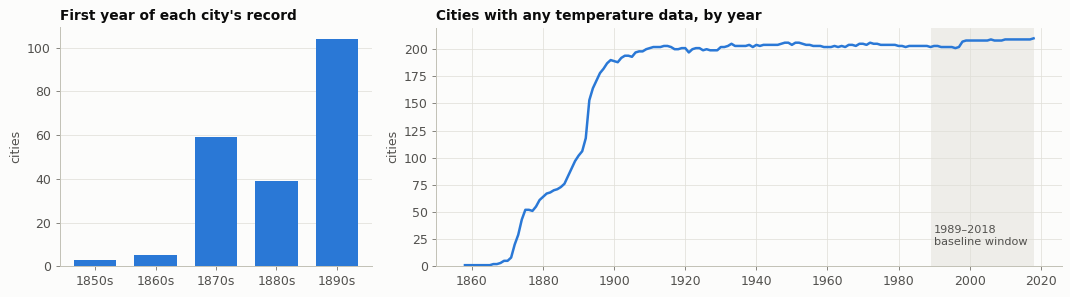

Years in which some city has no temperature data at all (after 1900):
                        min   max  count
Name                                    
Aiken                  1900  1900      1
Akron                  1953  1998     46
Asheville              1900  1963     64
Ashland                1900  1904      5
Athens                 1900  1901      2
Beckley                1928  1929      2
Birmingham             1904  1929     26
Charleston             1900  1901      2
Cincinnati             1916  1945     30
Clayton                1900  1995     13
CollegeStation         1908  1909      2
ColumbiaMO             1949  1968     20
CrescentCity           1910  1912      3
EUGENE                 1900  1911     12
Elko                   1906  1908      3
Ely                    1905  1937     26
Escondido              2009  2009      1
FortMyers              1900  1997      5
GlensFalls             1931  1941      9
Goodland               1900  1905      6
GreenvilleSpartanburg  1918 

In [16]:
any_temp = annual["Miss Tmax"] < annual["days_in_year"]           # at least one Tmax value that year
reporting = annual[any_temp].groupby("Year")["ID"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 2]})
first = span["min"].groupby((span["min"] // 10) * 10).size()
axes[0].bar(first.index.astype(str) + "s", first.values, color=SERIES[0], width=0.7)
axes[0].set_title("First year of each city's record")
axes[0].set_ylabel("cities"); axes[0].grid(axis="x", visible=False)
axes[1].plot(reporting.index, reporting.values, color=SERIES[0])
axes[1].set_title("Cities with any temperature data, by year")
axes[1].set_ylabel("cities"); axes[1].set_ylim(0, 220)
axes[1].axvspan(*WINDOW, color=GRID, alpha=0.5, lw=0)
axes[1].text(WINDOW[0] + 1, 20, "1989–2018\nbaseline window", color=INK2, fontsize=9)
plt.tight_layout(); plt.show()
print("Years in which some city has no temperature data at all (after 1900):")
print(annual[(~any_temp) & (annual.Year >= 1900)].groupby("Name")["Year"].agg(["min", "max", "count"]))

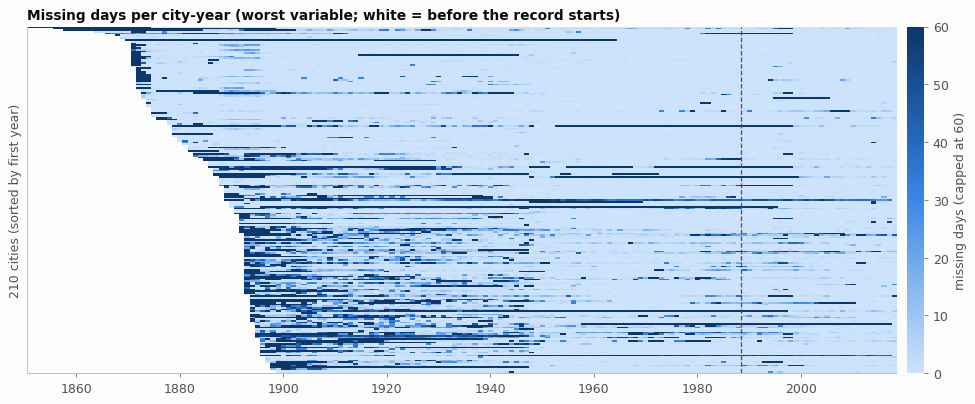

In [17]:
# Missing days per city-year (worst of Tmax, Tmin, Prcp), capped at 60 so small gaps are visible
annual["miss_worst"] = annual[["Miss Tmax", "Miss Tmin", "Miss Prcp"]].max(axis=1)
grid = annual.pivot(index="ID", columns="Year", values="miss_worst").loc[span["min"].sort_values().index]

fig, ax = plt.subplots(figsize=(12, 4.6))
im = ax.imshow(grid.clip(upper=60).to_numpy(dtype=float), aspect="auto", cmap=SEQ, interpolation="nearest",
               extent=[grid.columns.min() - 0.5, grid.columns.max() + 0.5, len(grid), 0])
ax.grid(False); ax.set_yticks([]); ax.set_ylabel("210 cities (sorted by first year)")
ax.axvline(WINDOW[0] - 0.5, color=INK2, lw=1, ls="--")
ax.set_title("Missing days per city-year (worst variable; white = before the record starts)")
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("missing days (capped at 60)"); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()

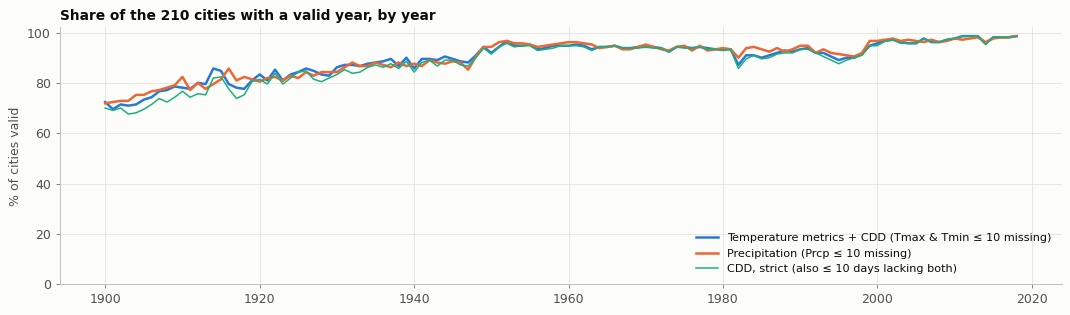

Average % valid per decade:
      Temperature metrics + CDD (Tmax & Tmin ≤ 10 missing)  Precipitation (Prcp ≤ 10 missing)  CDD, strict (also ≤ 10 days lacking both)
Year                                                                                                                                    
1960                                             94.300                                94.700                                     94.100
1970                                             93.900                                93.900                                     93.700
1980                                             91.400                                93.000                                     90.700
1990                                             91.700                                92.800                                     91.000
2000                                             96.400                                96.800                                     96.300
2010         

In [18]:
# Share of cities whose year counts for scoring (official 10-day rule), by year
temp_ok = (annual[["Miss Tmax", "Miss Tmin"]].max(axis=1) <= MAX_MISSING_DAYS)
prcp_ok = annual["Miss Prcp"] <= MAX_MISSING_DAYS
cov = annual[["ID", "Year", "days_in_year"]].join(coverage["Days Both"])
cdd_strict_ok = temp_ok & (cov["days_in_year"] - cov["Days Both"] <= MAX_MISSING_DAYS)
share = pd.DataFrame({"Temperature metrics + CDD (Tmax & Tmin ≤ 10 missing)": temp_ok,
                      "Precipitation (Prcp ≤ 10 missing)": prcp_ok,
                      "CDD, strict (also ≤ 10 days lacking both)": cdd_strict_ok,
                      "Year": annual["Year"]}).query("Year >= 1900").groupby("Year").mean() * 100

fig, ax = plt.subplots(figsize=(12, 3.6))
for i, col in enumerate(share.columns):
    ax.plot(share.index, share[col], color=SERIES[i], lw=2 if i < 2 else 1.2, label=col)
ax.set_ylabel("% of cities valid"); ax.set_ylim(0, 102)
ax.set_title("Share of the 210 cities with a valid year, by year")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()
print("Average % valid per decade:")
print(share.groupby((share.index // 10) * 10).mean().round(1).tail(6))

In [19]:
# The baseline window: how many valid years does each city have per target (1989–2018)?
win = valid.query("@WINDOW[0] <= year <= @WINDOW[1]")
valid_years = win.groupby("city_id")[TARGETS].count()
summary = pd.DataFrame({
    "median valid years": valid_years.median(),
    "min valid years": valid_years.min(),
    "cities with all 30": (valid_years == 30).sum(),
    "cities < 25": (valid_years < 25).sum(),
    f"cities < {MIN_VALID_YEARS} (not scored)": (valid_years < MIN_VALID_YEARS).sum(),
    "invalid city-years": 30 * 210 - valid_years.sum(),
})
display(summary)
worst = valid_years.assign(name=NAME).sort_values("total_precip_in").head(8)
print("Cities with the fewest valid years in 1989–2018:"); display(worst)

,median valid years,min valid years,cities with all 30,cities < 25,cities < 10 (not scored),invalid city-years
annual_avg_temp,30.000,1,165,19,2,304
total_precip_in,30.000,1,163,15,3,276
hottest_day_temp,30.000,1,165,19,2,304
cdd,30.000,1,165,19,2,304


Cities with the fewest valid years in 1989–2018:


,annual_avg_temp,total_precip_in,hottest_day_temp,cdd,name
city_id,,,,,
USW00003856,1,1,1,1,Huntsville
USW00014935,30,1,30,30,GrandIsland
USW00024121,30,1,30,30,Elko
USW00014895,16,17,16,16,Akron
USC00380072,16,17,16,16,Aiken
USW00093821,19,19,19,19,Louisville
USW00014894,18,20,18,18,Wheeling
USW00014792,20,20,20,20,Trenton


## 5. Geography

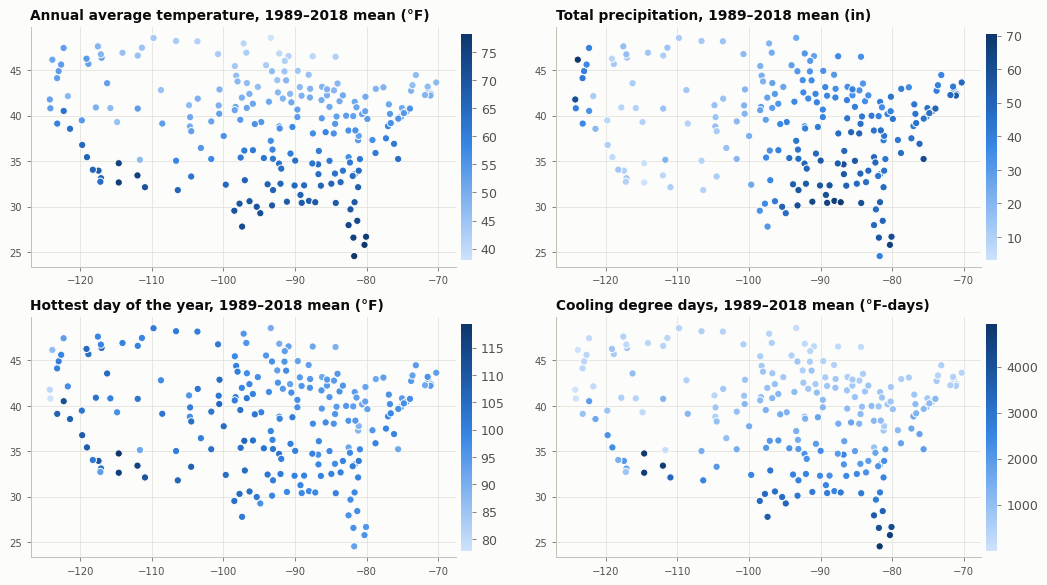

Lat 24.6–48.6, Lon -124.2–-70.3: contiguous U.S. only (no Alaska or Hawaii).

Correlation of the city means with location:
                    lat    lon
annual_avg_temp  -0.930  0.030
total_precip_in  -0.390  0.630
hottest_day_temp -0.290 -0.420
cdd              -0.880  0.110


In [20]:
city_means = win.groupby("city_id")[TARGETS].mean().join(city_curated.set_index("city_id")[["name", "lat", "lon"]])

fig, axes = plt.subplots(2, 2, figsize=(12, 6.6))
for ax, m in zip(axes.flat, TARGETS):
    sc = ax.scatter(city_means["lon"], city_means["lat"], c=city_means[m], cmap=SEQ, s=34,
                    edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(f"{LABEL[m]}, 1989–2018 mean ({UNITS[m]})")
    ax.set_aspect(1 / np.cos(np.radians(38)))
    ax.tick_params(labelsize=8)
    cb = fig.colorbar(sc, ax=ax, pad=0.01, shrink=0.85); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()
print(f"Lat {city_means.lat.min():.1f}–{city_means.lat.max():.1f}, Lon {city_means.lon.min():.1f}–{city_means.lon.max():.1f}: "
      "contiguous U.S. only (no Alaska or Hawaii).")
print("\nCorrelation of the city means with location:")
print(city_means[TARGETS + ["lat", "lon"]].corr().loc[TARGETS, ["lat", "lon"]].round(2))

## 6. The four target metrics

Uses the curated `data/annual_valid.csv` (invalid city-years already empty), 1989–2018 unless stated.

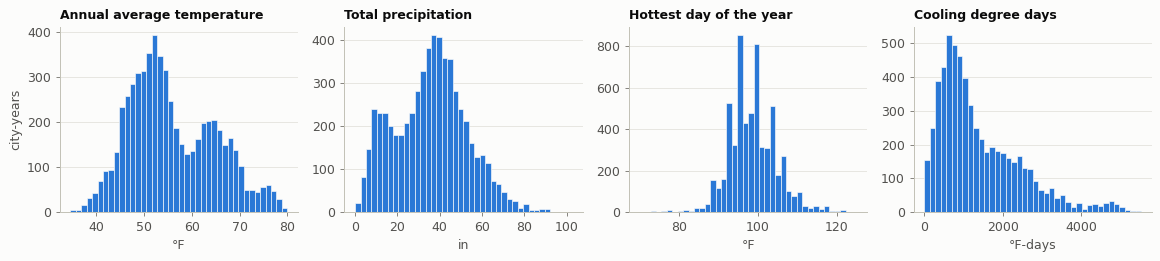

,count,mean,std,min,25%,50%,75%,max
annual_avg_temp,"5,996.000",55.809,9.005,34.580,49.078,53.940,62.920,79.970
total_precip_in,"6,024.000",35.656,17.015,0.030,23.087,36.485,46.655,102.490
hottest_day_temp,"5,996.000",98.551,6.119,70.000,95.000,98.000,102.000,125.000
cdd,"5,996.000","1,397.688","1,054.593",0.000,622.500,"1,068.500","1,985.000","5,538.750"


In [21]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, m in zip(axes, TARGETS):
    ax.hist(win[m].dropna(), bins=40, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(LABEL[m], fontsize=10); ax.set_xlabel(UNITS[m]); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("city-years")
plt.tight_layout(); plt.show()
display(win[TARGETS].describe().T)

In [22]:
# Where is the variance? Between cities (climate) vs within a city (year-to-year weather)
anom = win.set_index(["city_id", "year"])[TARGETS]
anom = anom - anom.groupby("city_id").transform("mean")          # within-city anomalies


def trend_per_decade(s):
    s = s.dropna()
    return np.polyfit(s.index.get_level_values("year"), s.values, 1)[0] * 10 if len(s) >= 20 else np.nan


trends = win.set_index(["city_id", "year"])[TARGETS].groupby("city_id").agg(trend_per_decade)
lag1 = {m: anom[m].groupby("city_id").apply(lambda s: s.droplevel(0).sort_index().autocorr(1)).mean()
        for m in TARGETS}

variance = pd.DataFrame({
    "between-city std": win.groupby("city_id")[TARGETS].mean().std(),
    "within-city std": win.groupby("city_id")[TARGETS].std().mean(),
    "lag-1 autocorr of anomaly (mean)": pd.Series(lag1),
    "trend per decade, median city": trends.median(),
    "% cities with upward trend": (trends > 0).mean() * 100,
    "MAE of 30-yr mean (in-sample)": anom.abs().mean(),
})
variance["between / within"] = variance["between-city std"] / variance["within-city std"]
variance.round(3)

,between-city std,within-city std,lag-1 autocorr of anomaly (mean),"trend per decade, median city",% cities with upward trend,MAE of 30-yr mean (in-sample),between / within
annual_avg_temp,8.899,1.404,0.278,0.538,91.429,1.134,6.340
total_precip_in,15.345,7.118,0.009,0.393,60.476,5.604,2.156
hottest_day_temp,5.302,3.081,0.088,0.287,66.190,2.427,1.721
cdd,"1,032.900",199.328,0.168,89.671,91.429,159.418,5.182


- **Between-city differences dwarf year-to-year noise.** A model only needs each city's level right
  plus a small adjustment; the score is decided by that adjustment.
- **Persistence (lag-1 autocorrelation) is positive for temperature and CDD**: partly genuine
  persistence, partly the warming trend. It is weak for precipitation and the hottest day: those
  two are close to unpredictable noise around the mean, which matches the team's backtests (nothing
  beat the 30-year average on them).
- Note the in-sample MAE of the 30-year mean: the real (out-of-sample) baseline MAE is larger.

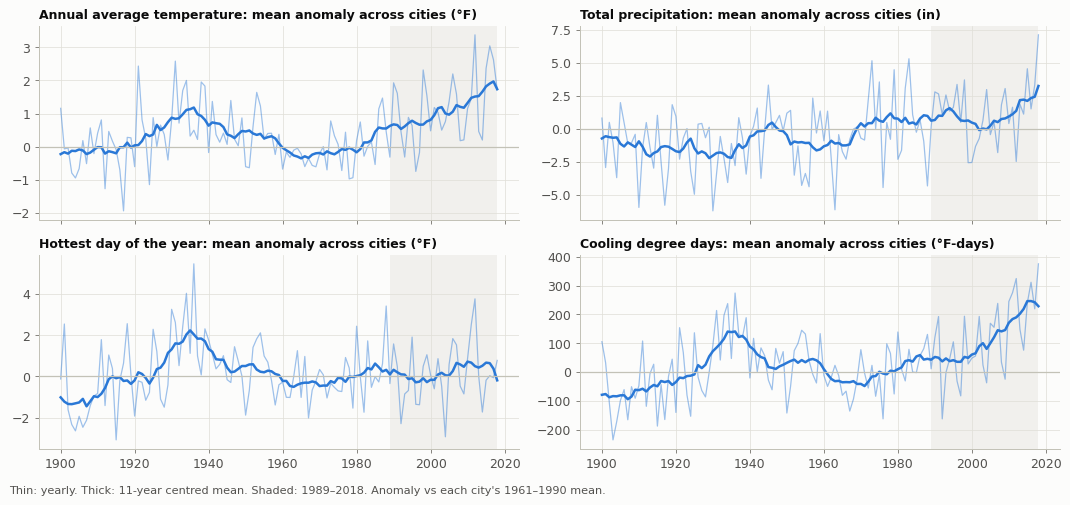

In [23]:
# Long-run picture: average anomaly across cities vs each city's 1961–1990 mean
full = valid.set_index(["city_id", "year"])[TARGETS]
ref = full.loc[(slice(None), slice(1961, 1990)), :].groupby("city_id").mean()
national = (full - ref).groupby("year").mean().loc[1900:]

fig, axes = plt.subplots(2, 2, figsize=(12, 5.6), sharex=True)
for ax, m in zip(axes.flat, TARGETS):
    ax.plot(national.index, national[m], color=SERIES[0], lw=1, alpha=0.45)
    ax.plot(national.index, national[m].rolling(11, center=True, min_periods=6).mean(), color=SERIES[0], lw=2)
    ax.axhline(0, color=AXIS, lw=1)
    ax.axvspan(*WINDOW, color=GRID, alpha=0.4, lw=0)
    ax.set_title(f"{LABEL[m]}: mean anomaly across cities ({UNITS[m]})", fontsize=10)
fig.text(0.01, 0.01, "Thin: yearly. Thick: 11-year centred mean. Shaded: 1989–2018. Anomaly vs each city's 1961–1990 mean.",
         color=INK2, fontsize=9)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

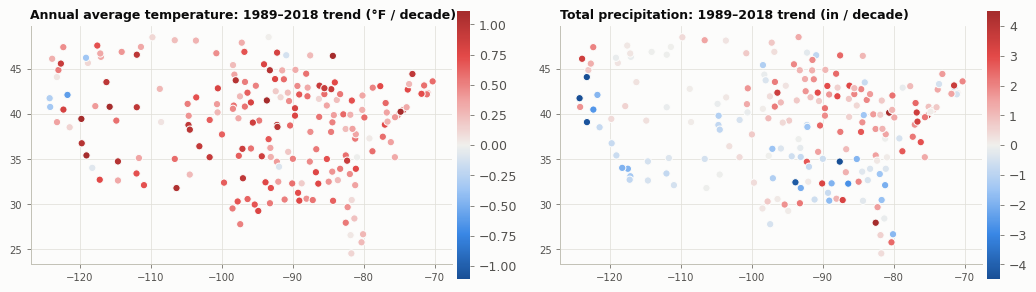

In [24]:
# Where has it warmed / got wetter? 1989–2018 linear trend per city
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m in zip(axes, ["annual_avg_temp", "total_precip_in"]):
    t = trends[m].dropna(); lim = np.nanpercentile(np.abs(t), 98)
    sc = ax.scatter(city_means.loc[t.index, "lon"], city_means.loc[t.index, "lat"], c=t, cmap=DIV,
                    norm=TwoSlopeNorm(0, -lim, lim), s=34, edgecolor=SURFACE, linewidth=0.8)
    ax.set_aspect(1 / np.cos(np.radians(38))); ax.tick_params(labelsize=8)
    ax.set_title(f"{LABEL[m]}: 1989–2018 trend ({UNITS[m]} / decade)", fontsize=10)
    cb = fig.colorbar(sc, ax=ax, pad=0.01, shrink=0.85); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()

## 7. Data quality

What needs fixing before the raw table can be modelled. Each check below states the problem, how
many rows it affects, and (in section 10) what the cleaning does about it.

### 7.1 Sentinels: ±∞ and fake zeros in years with no data

In [25]:
num = annual.select_dtypes("number")
inf_cols = np.isinf(num).sum().loc[lambda s: s > 0]
all_missing = {"Tmax": annual["Miss Tmax"] >= annual["days_in_year"],
               "Tmin": annual["Miss Tmin"] >= annual["days_in_year"],
               "Prcp": annual["Miss Prcp"] >= annual["days_in_year"]}
print("±inf values per column:"); print(inf_cols.to_string())
print("\nDo the ±inf rows coincide exactly with years where that variable has no data at all?")
for col, var in [("Max Tmax", "Tmax"), ("Min Tmin", "Tmin"), ("Max 1-day P", "Prcp")]:
    print(f"  {col:12s} ±inf ⇔ all {var} missing: {(np.isinf(annual[col]) == all_missing[var]).all()}")

prcp_cols = ["ToT Prcp", "Max 5-day P", "Wet Days"]
print("\nPrecipitation in years with NO precipitation data (should be NaN, stored as):")
print(annual.loc[all_missing["Prcp"], prcp_cols].describe().loc[["count", "min", "max"]])
print(f"\nToT Prcp == 0: {(annual['ToT Prcp'] == 0).sum()} rows, of which "
      f"{(all_missing['Prcp'] & (annual['ToT Prcp'] == 0)).sum()} are years without any data (fake zeros).")
pct = ["Warm Days", "Warm Nights", "Cold Days", "Cold Nights"]
print("Percentage indices in years with no temperature data (should be NaN):",
      annual.loc[all_missing["Tmax"], pct].abs().sum().sum(), "= all zeros")

±inf values per column:
Max Tmax       1184
Min Tmax       1184
Max Tmin       1174
Min Tmin       1174
Max 1-day P     932

Do the ±inf rows coincide exactly with years where that variable has no data at all?
  Max Tmax     ±inf ⇔ all Tmax missing: True
  Min Tmin     ±inf ⇔ all Tmin missing: True
  Max 1-day P  ±inf ⇔ all Prcp missing: True

Precipitation in years with NO precipitation data (should be NaN, stored as):
       ToT Prcp  Max 5-day P  Wet Days
count   932.000      932.000   932.000
min       0.000        0.000     0.000
max       0.000        5.800     0.000

ToT Prcp == 0: 935 rows, of which 932 are years without any data (fake zeros).
Percentage indices in years with no temperature data (should be NaN): 179.71 = all zeros


**Finding:** a year with no data for a variable is stored as `±inf` (extremes), `0` (totals,
percentages) or NaN (means). Naïve averaging would treat 932 precipitation zeros as real droughts and
±∞ would break any model. The fix is to set them to NaN, which the 10-day validity rule also does
(section 10). Up to 2017 some cities have whole years like this, so it is not only an early-record issue.

### 7.2 Partial years read low

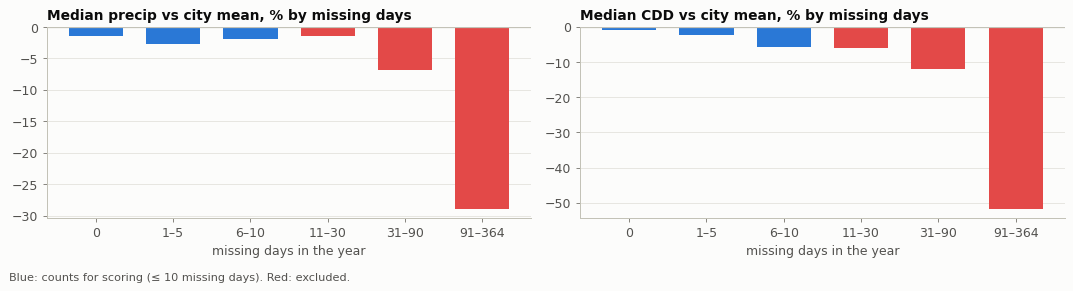

,city-years (prcp),"precip vs city mean, %",city-years (temp),"CDD vs city mean, %","Avg Temp vs city mean, °F"
missing days,,,,,
0,20655,-1.460,18069,-1.010,-0.070
1–5,1573,-2.730,3541,-2.310,-0.050
6–10,211,-1.880,752,-5.610,-0.030
11–30,588,-1.430,864,-5.910,0.060
31–90,825,-6.930,604,-11.860,0.070
91–364,438,-28.950,335,-51.790,-1.200


In [26]:
# How biased are totals when days are missing? Compare with each city's mean over complete years.
df = annual[["ID", "Year", "Miss Prcp", "Miss Tmax", "Miss Tmin", "ToT Prcp", "cdd", "Avg Temp"]].query("Year >= 1900").copy()
complete_p = df["Miss Prcp"] == 0
complete_t = df[["Miss Tmax", "Miss Tmin"]].max(axis=1) == 0
df["prcp_pct"] = 100 * (df["ToT Prcp"] / df.loc[complete_p].groupby("ID")["ToT Prcp"].mean().reindex(df["ID"]).values - 1)
df["cdd_pct"] = 100 * (df["cdd"] / df.loc[complete_t].groupby("ID")["cdd"].mean().reindex(df["ID"]).values - 1)
df["temp_dev"] = df["Avg Temp"] - df.loc[complete_t].groupby("ID")["Avg Temp"].mean().reindex(df["ID"]).values
bins = [-1, 0, 5, 10, 30, 90, 364]
labels = ["0", "1–5", "6–10", "11–30", "31–90", "91–364"]
df["miss_p_bin"] = pd.cut(df["Miss Prcp"], bins, labels=labels)
df["miss_t_bin"] = pd.cut(df[["Miss Tmax", "Miss Tmin"]].max(axis=1), bins, labels=labels)
bias = pd.DataFrame({
    "city-years (prcp)": df.groupby("miss_p_bin", observed=False).size(),
    "precip vs city mean, %": df.groupby("miss_p_bin", observed=False)["prcp_pct"].median(),
    "city-years (temp)": df.groupby("miss_t_bin", observed=False).size(),
    "CDD vs city mean, %": df.groupby("miss_t_bin", observed=False)["cdd_pct"].median(),
    "Avg Temp vs city mean, °F": df.groupby("miss_t_bin", observed=False)["temp_dev"].median(),
})
bias.index.name = "missing days"

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, col in zip(axes, ["precip vs city mean, %", "CDD vs city mean, %"]):
    ax.bar(bias.index.astype(str), bias[col], color=[SERIES[0]] * 3 + [SERIES[7]] * 3, width=0.7)
    ax.axhline(0, color=AXIS, lw=1); ax.grid(axis="x", visible=False)
    ax.set_title(f"Median {col} by missing days"); ax.set_xlabel("missing days in the year")
fig.text(0.01, 0.01, "Blue: counts for scoring (≤ 10 missing days). Red: excluded.", color=INK2, fontsize=9)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()
bias.round(2)

**Finding:** totals are biased low roughly in proportion to the missing days, while the
mean temperature barely moves (it is a mean, not a sum). Within the ≤ 10-day band the bias is small but
not zero. A possible later refinement: scale `ToT Prcp` and `cdd` by `days_in_year / days observed`
for the 1–10 missing-day years used in training (do not do this for evaluation: the scoring uses raw values).

### 7.3 Daily values: impossible or extreme readings

In [27]:
bad_order = daily[daily["tmax"] < daily["tmin"]]
print(f"Days with tmax < tmin: {len(bad_order)}")
display(bad_order.assign(Name=bad_order["ID"].map(NAME)).head(10))

print("Physical range checks:",
      {"tmax > 130 °F": int((daily.tmax > 130).sum()), "tmin < -70 °F": int((daily.tmin < -70).sum()),
       "prcp < 0": int((daily.prcp < 0).sum()), "prcp > 15 in/day": int((daily.prcp > 15).sum())})
display(daily.nlargest(5, "prcp").assign(Name=lambda d: d["ID"].map(NAME))[["Name", "Date", "prcp"]])

# Statistical outliers: |z| > 5 within the same city and calendar month
month = daily["Date"].dt.month
for v in ["tmax", "tmin"]:
    g = daily.groupby([daily["ID"], month])[v]
    z = (daily[v] - g.transform("mean")) / g.transform("std")
    out = daily.loc[z.abs() > 5, ["ID", "Date", v]].assign(z=z[z.abs() > 5])
    print(f"{v}: {len(out)} readings with |z| > 5 within city-month "
          f"({len(out) / daily[v].notna().sum() * 1e6:.1f} per million); "
          f"{(out['Date'].dt.year >= WINDOW[0]).sum()} of them in 1989–2018")
    display(out.assign(Name=out["ID"].map(NAME)).reindex(out["z"].abs().sort_values(ascending=False).index).head(5))

Days with tmax < tmin: 9


,ID,Date,tmax,tmin,prcp,Year,Name
5657217,USW00094850,1882-12-22,37.000,38.000,0.180,1882,Marquette
6361295,USW00013895,1917-09-06,71.000,72.000,0.000,1917,Montgomery
7481954,USC00356749,1999-12-13,51.000,53.000,0.010,1999,Portland
8460852,USW00014847,1889-02-04,15.000,16.000,0.080,1889,SaultSteMarie
8464699,USW00014847,1899-08-18,55.000,59.000,0.000,1899,SaultSteMarie
9779191,USW00014897,1918-08-06,61.000,66.000,0.050,1918,Wausau
9960193,USW00094014,1896-02-29,4.000,10.000,0.060,1896,Williston
9972567,USW00094014,1930-01-16,-29.000,-28.000,0.000,1930,Williston
9978426,USW00094014,1946-01-31,-17.000,-6.000,0.050,1946,Williston


Physical range checks: {'tmax > 130 °F': 0, 'tmin < -70 °F': 0, 'prcp < 0': 0, 'prcp > 15 in/day': 7}


,Name,Date,prcp
4889439,KeyWest,1980-11-11,22.750
4879944,KeyWest,1954-11-13,17.050
4322506,Houston,2017-08-27,16.070
5032069,LakeCharles,1980-05-16,15.670
7183323,Pensacola,2014-04-29,15.550


tmax: 247 readings with |z| > 5 within city-month (25.6 per million); 40 of them in 1989–2018


,ID,Date,tmax,z,Name
3443662,USW00012923,1903-06-14,63.000,-7.227,Galveston
8446368,USW00023188,1979-06-10,101.000,6.954,SanDiego
3014130,USW00024213,1903-06-06,85.000,6.795,Eureka
3029482,USW00024213,1945-06-17,85.000,6.795,Eureka
8447105,USW00023188,1981-06-16,100.000,6.727,SanDiego


tmin: 261 readings with |z| > 5 within city-month (27.0 per million); 25 of them in 1989–2018


,ID,Date,tmin,z,Name
7048692,USW00012815,1910-09-20,50.000,-7.639,Orlando
9180607,USW00012842,1897-09-22,54.000,-6.907,Tampa
4649312,USW00013889,1984-06-01,47.000,-6.619,Jacksonville
4276482,USW00012960,1891-08-24,54.000,-6.572,Houston
9165519,USW00093805,1984-06-01,46.000,-6.440,Tallahassee


**Finding:** the daily data are very clean. A handful of `tmax < tmin` days and a few dozen extreme
z-scores (mostly before 1989) cannot move a yearly mean. Some extreme readings may be real
(cold outbreaks, hurricanes), so they are **flagged, not deleted**. Note that `hottest_day_temp` is a
single daily maximum, so one bad reading does change that target; the outlier list above is worth a
look before trusting extremes from a given city.

### 7.4 Can we rebuild the annual targets from `daily`?

If yes, we know exactly how the targets are defined, and we can safely build new features from the
daily data later (e.g., seasonal means, heat-wave counts).

In [28]:
d = daily[daily["Year"] >= WINDOW[0]]
g = d.groupby(["ID", "Year"])
both = d[["tmax", "tmin"]].notna().all(axis=1)
tavg = ((d["tmax"] + d["tmin"]) / 2).where(both)
rebuilt = pd.DataFrame({
    "Avg Temp": (g["tmax"].mean() + g["tmin"].mean()) / 2,
    "ToT Prcp": g["prcp"].sum(),
    "Max Tmax": g["tmax"].max(),
    "cdd": (tavg - 65).clip(lower=0).groupby([d["ID"], d["Year"]]).sum(min_count=1),
    "Days Both": both.groupby([d["ID"], d["Year"]]).sum(),
})
stored = annual.join(coverage["Days Both"]).set_index(["ID", "Year"]).loc[rebuilt.index, rebuilt.columns]
stored = stored.replace([np.inf, -np.inf], np.nan)          # ±inf sentinels: no data that year
diff = (rebuilt - stored).abs()
both_present = rebuilt.notna() & stored.notna()
pd.DataFrame({"city-years compared": both_present.sum(),
              "only one side has a value": (rebuilt.notna() != stored.notna()).sum(),
              "max |diff|": diff.max(),
              "share within 0.01": (diff[both_present] <= 0.01).sum() / both_present.sum()}).round(4)

,city-years compared,only one side has a value,max |diff|,share within 0.01
Avg Temp,6197,0,0.010,1.000
ToT Prcp,6300,0,0.000,1.000
Max Tmax,6197,0,0.000,1.000
cdd,6196,0,0.000,1.000
Days Both,6300,0,0.000,1.000


In [29]:
# CDD validity: years that pass the official Tmax/Tmin rule but lack both values on > 10 days
cdd_gap = annual.join(coverage["Days Both"]).assign(lacking_both=lambda x: x["days_in_year"] - x["Days Both"])
cdd_gap = cdd_gap[(cdd_gap[["Miss Tmax", "Miss Tmin"]].max(axis=1) <= MAX_MISSING_DAYS)
                  & (cdd_gap["lacking_both"] > MAX_MISSING_DAYS) & cdd_gap["Year"].between(*WINDOW)]
print(f"{len(cdd_gap)} city-years in 1989–2018 pass the rule but miss both values on > 10 days (CDD reads low):")
cdd_gap[["Name", "Year", "Miss Tmax", "Miss Tmin", "Days Both", "lacking_both", "cdd"]]

18 city-years in 1989–2018 pass the rule but miss both values on > 10 days (CDD reads low):


,Name,Year,Miss Tmax,Miss Tmin,Days Both,lacking_both,cdd
360,Aiken,1994,8,4,353,12,"1,913.500"
366,Aiken,2000,6,7,354,12,"2,238.000"
511,Akron,2014,9,10,354,11,668.000
1159,Ashland,1989,8,5,352,13,332.000
2509,Belvidere,1993,1,10,354,11,744.000
8210,Escondido,1993,7,7,353,12,"1,301.500"
8212,Escondido,1995,7,10,353,12,"1,262.500"
10904,Gulfport,1996,8,6,355,11,"2,474.000"
11153,Hastings,1994,4,9,352,13,947.500
11154,Hastings,1995,9,8,348,17,934.000


In [30]:
# Precision: the dataset card says 2018 values partly carry one decimal (converted GHCN-D data)
frac = daily.loc[daily["Year"] >= 2010].assign(frac=lambda x: (x["tmax"] % 1 != 0) & x["tmax"].notna())
print("Share of daily tmax with a decimal, by year:")
print((frac.groupby("Year")["frac"].mean() * 100).round(2).to_string())

Share of daily tmax with a decimal, by year:
Year
2010    0.000
2011    0.000
2012    0.000
2013    0.000
2014    0.000
2015    0.000
2016    0.000
2017    0.000
2018   47.380


**Finding:** the definitions match the dataset card: all four targets (and `Days Both`) are rebuilt
from `daily` to within rounding (0.01 °F on `Avg Temp`), so features derived from `daily` are
consistent with the targets.
The 2018 decimals are a precision change, not a level change: harmless for annual means.

## 8. Station changes

Each city's record stitches several stations together. When the station moves (e.g., downtown → airport),
the level of the record can jump with no change in climate. A trend fitted across a jump is biased.

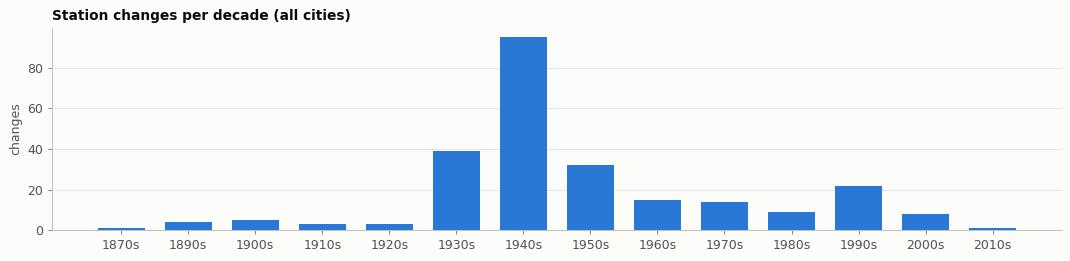

32 station changes in 1989–2018, in 30 cities:


,ID,Name,Year,Station Segment,Station Changes
15719,USW00094040,McCook,1989,2,1
16250,USW00014711,MiddletownHarrisburg,1991,2,1
19255,USW00014942,Omaha,1994,4,1
6569,USW00003017,Denver,1995,2,1
27905,USW00003145,Yuma,1995,2,1
14919,USW00093821,Louisville,1995,3,1
26457,USW00094298,Vancouver,1996,1,1
23947,USW00014943,SiouxCity,1996,2,1
12866,USW00003963,Jefferson,1997,1,1
15727,USW00094040,McCook,1997,4,1


In [31]:
changes = coverage.loc[coverage["Station Changes"] > 0, ["ID", "Name", "Year", "Station Segment", "Station Changes"]]
per_decade = changes.groupby((changes["Year"] // 10) * 10)["Station Changes"].sum()

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(per_decade.index.astype(str) + "s", per_decade.values, color=SERIES[0], width=0.7)
ax.set_title("Station changes per decade (all cities)"); ax.set_ylabel("changes"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

recent = changes[changes["Year"].between(*WINDOW)]
print(f"{int(recent['Station Changes'].sum())} station changes in 1989–2018, in {recent['ID'].nunique()} cities:")
recent.sort_values("Year")

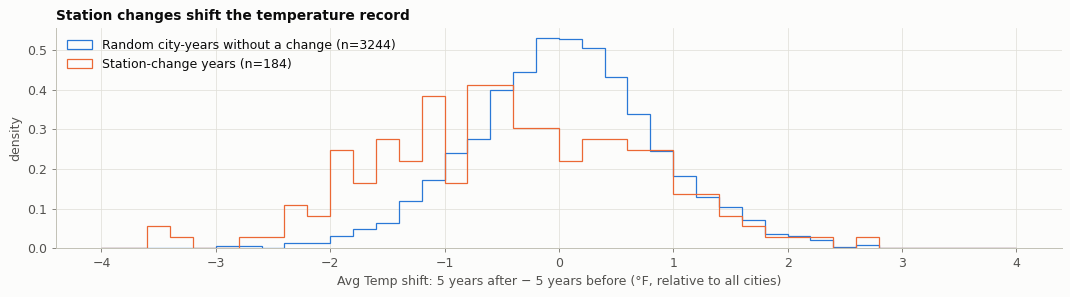

,mean shift (°F),std of shift (°F),share |shift| > 1 °F
no change,0.056,0.822,0.213
station change,-0.452,1.189,0.335


In [32]:
# How big are the jumps? Compare the 5 years after a change with the 5 years before.
# Remove the shared climate signal first: anomaly = city value − mean of all cities that year.
temp = annual.pivot(index="Year", columns="ID", values="Avg Temp")
temp = temp.where(annual.pivot(index="Year", columns="ID", values="miss_worst") <= MAX_MISSING_DAYS)
resid = temp - temp.mean(axis=1).values[:, None]


def step(city, year, k=5):
    before = resid.loc[year - k:year - 1, city]
    after = resid.loc[year + 1:year + k, city]
    return after.mean() - before.mean() if before.count() >= 3 and after.count() >= 3 else np.nan


ev = changes.query("1905 <= Year <= 2013").copy()
ev["step_F"] = [step(c, y) for c, y in zip(ev["ID"], ev["Year"])]
rng = np.random.default_rng(0)
change_set = set(zip(changes["ID"], changes["Year"]))
null_pairs = [(c, y) for c, y in zip(rng.choice(resid.columns, 4000), rng.integers(1905, 2014, 4000))
              if (c, y) not in change_set]
null = pd.Series([step(c, y) for c, y in null_pairs]).dropna()

fig, ax = plt.subplots(figsize=(12, 3.4))
b = np.linspace(-4, 4, 41)
ax.hist(null, bins=b, density=True, histtype="step", lw=2, color=SERIES[0], label=f"Random city-years without a change (n={len(null)})")
ax.hist(ev["step_F"].dropna(), bins=b, density=True, histtype="step", lw=2, color=SERIES[1], label=f"Station-change years (n={ev['step_F'].count()})")
ax.set_xlabel("Avg Temp shift: 5 years after − 5 years before (°F, relative to all cities)")
ax.set_ylabel("density"); ax.set_title("Station changes shift the temperature record"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
pd.DataFrame({"mean shift (°F)": [null.mean(), ev["step_F"].mean()],
              "std of shift (°F)": [null.std(), ev["step_F"].std()],
              "share |shift| > 1 °F": [(null.abs() > 1).mean(), (ev["step_F"].abs() > 1).mean()]},
             index=["no change", "station change"]).round(3)

,Name,Year,step_F
15727,McCook,1997,2.317
18175,Natchitoches,2010,-1.959
4418,Chicago,1980,-1.827
16931,Mitchell,1999,1.810
9362,Gainesville,1984,-1.525
25792,TriCities,1998,-1.427
12866,Jefferson,1997,1.365
22187,Russellville,1999,-1.200


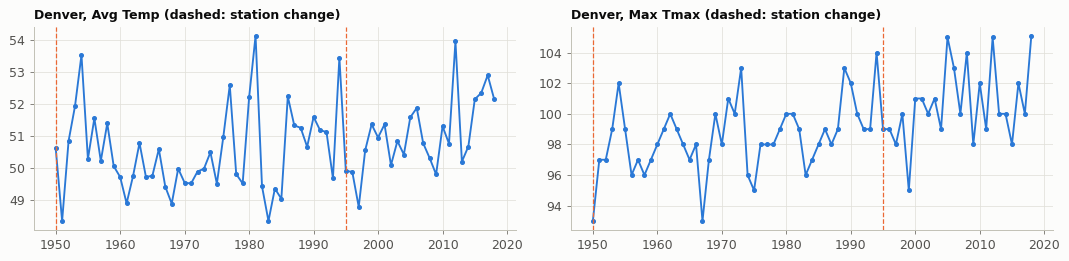

In [33]:
# Biggest recent jumps, and one example city
recent_steps = (ev.query("Year >= 1980").dropna(subset=["step_F"])
                .assign(abs_step=lambda x: x["step_F"].abs()).sort_values("abs_step", ascending=False).head(8))
display(recent_steps[["Name", "Year", "step_F"]])

city = "USW00003017"  # Denver: moved to Denver International Airport in 1995
ser = annual.set_index(["ID", "Year"]).loc[city, ["Avg Temp", "Max Tmax"]].loc[1950:]
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, col in zip(axes, ser.columns):
    ax.plot(ser.index, ser[col], color=SERIES[0], lw=1.5, marker="o", markersize=3)
    for y in changes.loc[changes["ID"] == city, "Year"]:
        if y >= 1950:
            ax.axvline(y, color=SERIES[1], lw=1, ls="--")
    ax.set_title(f"Denver, {col} (dashed: station change)", fontsize=10)
plt.tight_layout(); plt.show()

**Finding:** station-change years show a wider spread of level shifts than ordinary years (about a
third shift by more than 1 °F, against a fifth of ordinary years), and the shifts lean **cooler**,
consistent with moves from city centres to outlying airports. A change can move a city's record by
1–2 °F, as much as decades of warming. For modelling:

- Fit trends and 30-year means only on the **current station segment**, or add a step term at the
  change year (`Station Segment` gives the segments).
- The source lists **no station changes in 2019–2023**, so forecasts should start from the level of
  the current station.

## 9. Feature relationships

Correlations of **within-city anomalies** (each city's 1989–2018 mean removed, so geography does not
dominate), using valid years only. Same-year correlations show which features describe the same
weather; lag-1 correlations show which features *this year* carry information about the target
*next year*, which is what a forecast can use.

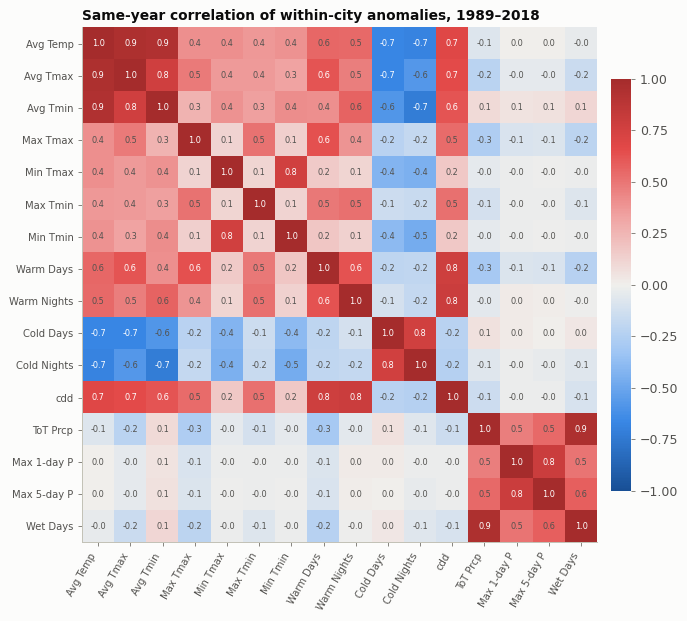

In [34]:
FEATURES = ["Avg Temp", "Avg Tmax", "Avg Tmin", "Max Tmax", "Min Tmax", "Max Tmin", "Min Tmin",
            "Warm Days", "Warm Nights", "Cold Days", "Cold Nights", "cdd",
            "ToT Prcp", "Max 1-day P", "Max 5-day P", "Wet Days"]
A = annual.set_index(["ID", "Year"])
ok = (A["miss_worst"] <= MAX_MISSING_DAYS)
X = A.loc[ok & A.index.get_level_values("Year").isin(range(WINDOW[0], WINDOW[1] + 1)), FEATURES]
X = X - X.groupby("ID").transform("mean")
corr = X.corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8); ax.grid(False)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="#ffffff" if abs(v) > 0.6 else INK2)
ax.set_title("Same-year correlation of within-city anomalies, 1989–2018")
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()

In [35]:
# Lag-1: feature anomaly in year t vs target anomaly in year t+1 (within city)
Xn = X.groupby("ID").shift(1)   # previous year's values (NaN across gaps is fine: rows are consecutive years)
prev_year_ok = X.index.get_level_values("Year").to_series().groupby(X.index.get_level_values("ID")).diff().values == 1
lag = pd.DataFrame({TARGET_COL[m]: Xn[prev_year_ok].corrwith(X.loc[prev_year_ok, TARGET_COL[m]]) for m in TARGETS})
lag.columns = [f"{m} (t+1)" for m in TARGETS]
print("Correlation of each feature this year with each target next year (within-city anomalies):")
lag.round(2).style.background_gradient(cmap=DIV, vmin=-0.4, vmax=0.4).format("{:.2f}")

Correlation of each feature this year with each target next year (within-city anomalies):


,annual_avg_temp (t+1),total_precip_in (t+1),hottest_day_temp (t+1),cdd (t+1)
Avg Temp,0.26,0.04,0.16,0.27
Avg Tmax,0.23,0.04,0.17,0.24
Avg Tmin,0.27,0.04,0.13,0.27
Max Tmax,0.04,-0.03,0.09,0.04
Min Tmax,-0.06,-0.03,-0.03,-0.04
Max Tmin,0.12,-0.05,0.12,0.13
Min Tmin,-0.09,-0.00,-0.05,-0.04
Warm Days,0.13,-0.00,0.14,0.11
Warm Nights,0.26,-0.01,0.15,0.22
Cold Days,-0.10,-0.00,-0.06,-0.17


**Finding:** the annual features form two tight groups that barely interact: a temperature group
(Avg Temp, Avg Tmax, Avg Tmin, CDD, warm/cold days) and a precipitation group (`ToT Prcp` and
`Wet Days` at 0.9). Feeding all of them to a model mostly duplicates information. Year-to-year
predictive signal is weak: the best lag-1 correlations are about 0.25 (mean temperatures and warm
nights → next year's temperature and CDD), and nothing predicts next year's precipitation. Next
year's hottest day follows this year's *mean* temperature (≈ 0.16) more than this year's hottest day
(≈ 0.09). Part of the temperature signal is the shared warming trend (anomalies here are not detrended). Expect gains to come
from **better level and trend estimation** (station segments, regional pooling, recent-years weighting)
rather than from last year's features.

## 10. Cleaning: one analysis-ready city-year table

Decisions, each tied to a finding above:

| Step | Rule | Why |
|---|---|---|
| 1 | `±inf` → NaN | Sentinels for "no data that year" (7.1) |
| 2 | Each column → NaN when its year misses > 10 days of the variable(s) it uses; the four targets use the official rule from `code/common.py` | Fake zeros (7.1) and partial years that read low (7.2); same rule as scoring |
| 3 | Keep `Days Both`; flag `cdd_short_days` where > 10 days lack both values | CDD reads low there (7.4); kept as a flag, not removed, because scoring uses the official rule |
| 4 | Add `station_segment`, `station_change`, `years_on_station` (years since this segment began; since the record began for segment 1), `is_current_station` | Level shifts at changes (8) |
| 5 | Add `n_tmax_lt_tmin` (daily readings with Tmax < Tmin) | Flag, values kept (7.3) |
| 6 | snake_case names; targets get their metric codes; add `lat`, `lon` | Consistent with `data/annual_valid.csv` |

Daily outliers are **not** removed (section 7.3): too few to matter for means, and some are real.

In [36]:
RULE = {  # column -> the missing-day columns of the variables it is computed from
    **{c: ["Miss Tmax"] for c in ["Avg Tmax", "Min Tmax", "Warm Days", "Cold Days"]},
    **{c: ["Miss Tmin"] for c in ["Avg Tmin", "Max Tmin", "Min Tmin", "Warm Nights", "Cold Nights"]},
    **{c: ["Miss Prcp"] for c in ["Max 1-day P", "Max 5-day P", "Wet Days"]},
    **{col: miss for col, miss in METRICS.values()},   # the 4 targets: official rule
}

clean = annual.drop(columns=["miss_worst"]).copy()
weather_cols = list(RULE)
before_nonnull = clean[weather_cols].replace([np.inf, -np.inf], np.nan).notna().sum()

# 1. sentinels
clean[weather_cols] = clean[weather_cols].replace([np.inf, -np.inf], np.nan)
# 2. validity rule per column
for col, miss in RULE.items():
    clean.loc[clean[miss].max(axis=1) > MAX_MISSING_DAYS, col] = np.nan
# 3. CDD coverage
clean["days_both"] = coverage["Days Both"].values
clean["cdd_short_days"] = (clean["days_in_year"] - clean["days_both"]) > MAX_MISSING_DAYS
# 4. stations
clean["station_segment"] = coverage["Station Segment"].values
clean["station_change"] = coverage["Station Changes"].values > 0
clean["years_on_station"] =clean.groupby(["ID", "station_segment"]).cumcount()
clean["is_current_station"] = clean["station_segment"] == clean.groupby("ID")["station_segment"].transform("max")
# 5. daily flags
n_bad = bad_order.groupby(["ID", "Year"]).size()
clean["n_tmax_lt_tmin"] = n_bad.reindex(pd.MultiIndex.from_frame(clean[["ID", "Year"]])).fillna(0).astype(int).values
# 6. names
rename = {v: k for k, v in TARGET_COL.items()}
clean = clean.rename(columns=rename).rename(columns=lambda c: c.lower().replace(" ", "_").replace("-", "").replace(".", ""))
clean = clean.rename(columns={"id": "city_id"})
assert_no_post_cutoff(clean, "year", "annual_clean")

print("Removed as invalid / sentinel, per column:")
after = clean[[rename.get(c, c).lower().replace(" ", "_").replace("-", "") for c in weather_cols]].notna().sum()
pd.DataFrame({"valid before": before_nonnull.values, "valid after": after.values,
              "set to NaN": before_nonnull.values - after.values}, index=after.index)

Removed as invalid / sentinel, per column:


,valid before,valid after,set to NaN
avg_tmax,26868,24868,2000
min_tmax,26868,24868,2000
warm_days,28052,24868,3184
cold_days,28052,24868,3184
avg_tmin,26878,24923,1955
max_tmin,26878,24923,1955
min_tmin,26878,24923,1955
warm_nights,28052,24923,3129
cold_nights,28052,24923,3129
max_1day_p,27120,24858,2262


In [37]:
# Cross-check: the four targets must equal the team's curated data/annual_valid.csv
ref = valid.set_index(["city_id", "year"])[TARGETS].sort_index()
mine = clean.set_index(["city_id", "year"])[TARGETS].round(3).sort_index()
same_nan = (ref.isna() == mine.isna()).all()
max_diff = (ref - mine).abs().max()
print(pd.DataFrame({"same NaN pattern": same_nan, "max |diff|": max_diff}))
assert same_nan.all() and (max_diff.fillna(0) < 1e-9).all(), "targets differ from data/annual_valid.csv"
print("\nOK: cleaned targets match data/annual_valid.csv exactly.")

                  same NaN pattern  max |diff|
annual_avg_temp               True       0.000
total_precip_in               True       0.000
hottest_day_temp              True       0.000
cdd                           True       0.000

OK: cleaned targets match data/annual_valid.csv exactly.


In [38]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out_path = PROCESSED_DIR / "meet_annual_clean.parquet"
clean.to_parquet(out_path, index=False)
print(f"Wrote {out_path.relative_to(ROOT)}  {clean.shape}  (git-ignored scratch; rebuild by running this notebook)")
print("\nColumns:", ", ".join(clean.columns))
clean.query("year >= 2016").head(3)

Wrote data/processed/meet_annual_clean.parquet  (28052, 32)  (git-ignored scratch; rebuild by running this notebook)

Columns: name, city_id, lat, lon, year, miss_tmax, miss_tmin, miss_prcp, annual_avg_temp, avg_tmax, avg_tmin, total_precip_in, hottest_day_temp, min_tmax, max_tmin, min_tmin, warm_days, warm_nights, cold_days, cold_nights, max_1day_p, max_5day_p, wet_days, cdd, days_in_year, days_both, cdd_short_days, station_segment, station_change, years_on_station, is_current_station, n_tmax_lt_tmin


,name,city_id,lat,lon,year,miss_tmax,miss_tmin,miss_prcp,annual_avg_temp,avg_tmax,avg_tmin,total_precip_in,hottest_day_temp,min_tmax,max_tmin,min_tmin,warm_days,warm_nights,cold_days,cold_nights,max_1day_p,max_5day_p,wet_days,cdd,days_in_year,days_both,cdd_short_days,station_segment,station_change,years_on_station,is_current_station,n_tmax_lt_tmin
123,Aberdeen,USW00014929,45.456,-98.413,2016,0,0,0,47.580,59.640,35.520,20.590,100.000,-2.000,73.000,-37.000,6.030,9.040,7.120,5.750,1.370,2.470,13.820,699.500,366,366,False,1,False,123,True,0
124,Aberdeen,USW00014929,45.456,-98.413,2017,0,0,0,44.770,57.400,32.150,15.220,104.000,-7.000,69.000,-32.000,5.480,3.840,10.140,9.320,2.980,3.510,9.740,530.500,365,365,False,1,False,124,True,0
125,Aberdeen,USW00014929,45.456,-98.413,2018,0,0,0,43.180,55.270,31.090,17.940,100.900,-8.900,73.900,-31.900,8.490,10.410,10.680,12.050,1.190,1.830,8.770,820.900,365,365,False,1,False,125,True,0


## 11. Findings and next steps

**Structure.** Four tables keyed on station `ID` (= `city_id`), 210 contiguous-U.S. cities, 1851–2018.
`annual_indices` (28,052 city-years, 19 weather columns) is computed from `daily` (10.2 M days), and the
four targets can be rebuilt from `daily`. `coverage_and_stations` adds coverage and station-segment
information row-for-row. No duplicate keys, gap years or missing calendar days.

**Coverage.** In the 1989–2018 baseline window about 95 % of city-years are valid (≈ 300 invalid per
temperature metric, 276 for precipitation). Most cities have all 30 years, but a few are thin:
Huntsville has a single valid year for every metric, Grand Island and Elko a single valid
precipitation year; 2–3 cities per metric fall below the 10 years the scoring needs.

**Data quality, and what the cleaning does.**

1. *Sentinels:* whole years without data are stored as ±∞ (extremes) or 0 (totals, percentages):
   932 fake zero-precipitation years → NaN.
2. *Partial years:* totals (precipitation, CDD) read low in proportion to missing days; the mean
   temperature barely moves → 10-day rule on every column (the official scoring rule for the
   targets). The cleaned targets match `data/annual_valid.csv` exactly.
3. *CDD coverage:* 18 city-years in 1989–2018 pass the rule but lack both temperatures on > 10 days → flagged.
4. *Daily data:* 9 days with Tmax < Tmin and ~500 extreme z-scores in 10 M days, mostly before 1989 → flagged, not removed.
5. *Station changes:* 32 in 1989–2018; about a third shift the level by > 1 °F, mostly cooler → segment flags for modelling.
6. *Precision:* 2018 daily values carry one decimal (earlier years whole °F): harmless for annual means.

**What it means for the model.**

- Differences between cities are 2–6 times larger than year-to-year variation; the score depends on
  getting each city's **recent level and drift** right.
- Temperature and CDD have risen in about 91 % of cities over 1989–2018 (median +0.54 °F and +90 °F-days
  per decade), with lag-1 autocorrelation of 0.28 and 0.17. Precipitation (0.01) and the hottest day (0.09)
  are mostly noise around the mean, so the 30-year mean is hard to beat there.
- Last year's anomalies carry little information about next year. Better level and trend estimates
  are the most promising direction.

**Feature-engineering ideas (next notebook).**

- Per city: means over several recent windows (5, 10, 15, 30 years), trend slopes, and both restricted
  to the current station segment; years since the last station change.
- Shrink noisy city trends towards a regional or neighbour average (cities as a spatial panel, using `lat`/`lon`).
- Seasonal features from `daily` (summer means, number of days above 90 °F, warm-night counts), which
  may track CDD and the hottest day better than annual means.
- Missing-day adjustment of totals for training years with 1–10 missing days.
- Physical relationships: CDD as a function of the summer temperature distribution, so a forecast
  of temperature can be turned into a consistent CDD forecast.

**External data (later).** Allowed: weather data up to 2018-12-31, and data that does not respond to the
weather from any year (elevation, distance to coast, land cover, urbanisation). Each source goes in `data/README.md`.